In [1]:
# EN: Install dependencies / PT: Instala as dependências
!pip install -q pandas numpy matplotlib

In [2]:
# EN: Download the project and generate synthetic data / PT: Baixa o projeto e gera os dados sintéticos
%cd /kaggle/working
!rm -rf projecao-fluxo-caixa
!git clone -q https://github.com/klaytonsi/projecao-fluxo-caixa.git
%cd projecao-fluxo-caixa
!python src/generate_data.py
!python src/database.py

/kaggle/working
/kaggle/working/projecao-fluxo-caixa
Meses: 12
Clientes com recebimento: 25
Fornecedores com pagamento: 15
Recebimentos: 1500
Pagamentos: 1000
Inadimplência: 11.07%
Saldo inicial: 50000.00
Banco criado: data/cashflow.db
Recebimentos: 1500
Pagamentos: 1000
Saldo inicial: 50000.00


In [3]:
# EN: Run base and scenarios A, B, C / PT: Roda a base e os cenários A, B, C
import sys
sys.path.insert(0, "src")
from scenarios import run_scenarios

summary, weekly = run_scenarios()
summary

,scenario,critical_week,weeks_negative,min_balance,final_balance
0,Base,3,4,-28630.67,135226.97
1,A: vendas -20%,2,9,-55131.06,26135.98
2,B: top 3 atrasam 30d,3,6,-43419.77,106256.83
3,C: A + B,2,11,-67874.11,2959.88


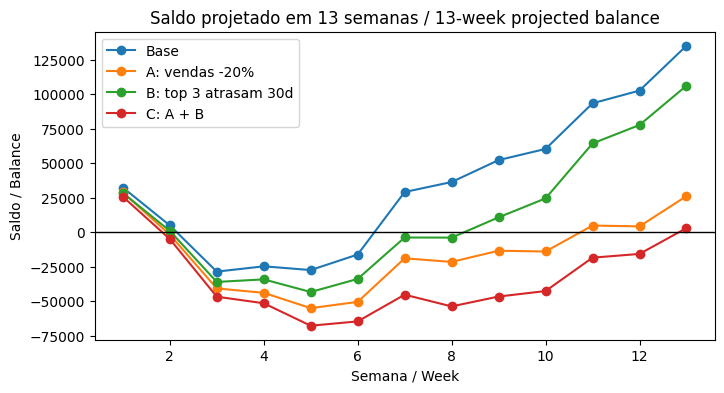

In [4]:
# EN: Plot the weekly balance of each scenario / PT: Gráfico do saldo semanal de cada cenário
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for name, df in weekly.items():
    ax.plot(df["week"], df["balance"], marker="o", label=name)
ax.axhline(0, color="black", linewidth=1)  # EN: zero line / PT: linha do zero
ax.set_xlabel("Semana / Week")
ax.set_ylabel("Saldo / Balance")
ax.set_title("Saldo projetado em 13 semanas / 13-week projected balance")
ax.legend()
plt.show()